In [1]:
# load the libraries
from torchvision import datasets, transforms, utils
import matplotlib.pyplot as plt
import torch
from torch import optim
import torch.nn as nn
import torch.nn.functional as F
import numpy as np
import os
import math
from tqdm.auto import tqdm
import time
from PIL import Image

In [2]:
#change to GPU if available
device=(torch.device('cuda') if torch.cuda.is_available() else torch.device('cpu'))
print(device)

cuda


In [3]:
#resize and load the data
transform=transforms.Compose([transforms.Resize((64, 64)),transforms.ToTensor(), transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))])
#change download to false if you already have the data in your local computer
train_dataset = datasets.Flowers102(root="data", split="train", transform=transform, download=True)
val_dataset   = datasets.Flowers102(root="data", split="val",   transform=transform, download=True)
test_dataset  = datasets.Flowers102(root="data", split="test",  transform=transform, download=True)

full_dataset=torch.utils.data.ConcatDataset([train_dataset, val_dataset, test_dataset]) #we use the whole dataset for training to generate new images

100%|██████████| 345M/345M [00:17<00:00, 20.1MB/s]
100%|██████████| 502/502 [00:00<00:00, 954kB/s]
100%|██████████| 15.0k/15.0k [00:00<00:00, 25.4MB/s]


In [8]:
class RESBLOC(nn.Module): #residual block
    def __init__(self, in_channels, out_channels, time_emb_dim=None):
        super().__init__()

        self.conv1=nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=1)
        self.bn1=nn.BatchNorm2d(out_channels)

        self.conv2 = nn.Conv2d(out_channels, out_channels, 3, padding=1)
        self.bn2 = nn.BatchNorm2d(out_channels)

        if time_emb_dim is not None:
            self.time_mlp = nn.Sequential(
                nn.SiLU(),
                nn.Linear(time_emb_dim, out_channels)
            )
        else:
            self.time_mlp = None

        if in_channels!=out_channels: #if the number in_channels is equal to out_channels we keep the information, otherwise we apply a convolution layer to it
            self.skip=nn.Conv2d(in_channels, out_channels, kernel_size=1)
        else:
            self.skip=nn.Identity()
    def forward(self, x, time_emb=None):
        residual=self.skip(x)

        out=F.silu(self.bn1(self.conv1(x)))

        if self.time_mlp is not None and time_emb is not None:
            time_scale = self.time_mlp(time_emb)
            out = out + time_scale[:, :, None, None]
        out=self.bn2(self.conv2(out))
        out+=residual #add the residual connections to preserve information from the input

        return out
class DOWNBLOCK(nn.Module): #downsampling block
    def __init__(self, in_channels, out_channels, time_emb_dim=None, depth=2):
        super().__init__()
        self.blocks = nn.ModuleList()

        self.blocks.append(RESBLOC(in_channels, out_channels, time_emb_dim))
        for _ in range(depth-1):
            self.blocks.append(RESBLOC(out_channels, out_channels, time_emb_dim))

        self.pool=nn.AvgPool2d(kernel_size=2)
    def forward(self, x, time_emb, skips):
        out=x
        for block in self.blocks:
            out=block(out, time_emb)
        skips.append(out) #store feature to use in skip connection later in the upsampling block
        out=self.pool(out) #to downsample (C, H, W)->(C, H//2, W//2)
        return out

class UPBLOCK(nn.Module): #upsampling block
    def __init__(self, in_channels, skip_channels, out_channels, time_emb_dim=None, depth=2):
        super().__init__()
        self.blocks=nn.ModuleList()
        self.up=nn.Upsample(scale_factor=2, mode="bilinear", align_corners=False) #to double the spatial dimensions
        self.blocks.append(RESBLOC(in_channels+skip_channels, out_channels, time_emb_dim))
        for _ in range(depth-1):
            self.blocks.append(RESBLOC(out_channels, out_channels, time_emb_dim))
    def forward(self, x, time_emb, skips):
        out=self.up(x)
        out=torch.cat([out, skips.pop()], dim=1) #giving a tensor with channels=in_channels+skip_channels
        for block in self.blocks:
            out=block(out, time_emb)
        return out

In [9]:
class SinusoidalPositionEmbeddings(nn.Module):
    def __init__(self, dim):
        super().__init__()
        self.dim = dim

    def forward(self, time):
        device = time.device
        half_dim = self.dim // 2
        embeddings = math.log(10000) / (half_dim - 1)
        embeddings = torch.exp(torch.arange(half_dim, device=device) * -embeddings) #exponential increasing for sinusoidal embeddings
        embeddings = time[:, None] * embeddings[None, :]
        embeddings = torch.cat((embeddings.sin(), embeddings.cos()), dim=-1)
        return embeddings

class UNET(nn.Module): #the final U_net architecture, which combines all the above building blocks
    def __init__(self, in_channels=3, out_channels=3, hidden_dims=[64, 128, 256, 512], time_emb_dim=256):
        super().__init__()

        self.time_mlp = nn.Sequential(
            SinusoidalPositionEmbeddings(time_emb_dim // 4),
            nn.Linear(time_emb_dim // 4, time_emb_dim),
            nn.SiLU(),
            nn.Linear(time_emb_dim, time_emb_dim)
        )

        self.init_conv = nn.Conv2d(in_channels, hidden_dims[0], kernel_size=3, padding=1)

        self.down_blocks = nn.ModuleList()
        for i in range(len(hidden_dims) - 1):
            self.down_blocks.append(DOWNBLOCK(in_channels=hidden_dims[i], out_channels=hidden_dims[i+1], time_emb_dim=time_emb_dim))

        self.mid_block1 = RESBLOC(hidden_dims[-1], hidden_dims[-1], time_emb_dim)
        self.mid_block2 = RESBLOC(hidden_dims[-1], hidden_dims[-1], time_emb_dim)

        self.up_blocks=nn.ModuleList()
        for i in range(len(hidden_dims)-1, 0, -1):
            self.up_blocks.append(UPBLOCK(in_channels=hidden_dims[i], skip_channels=hidden_dims[i], out_channels=hidden_dims[i-1], time_emb_dim=time_emb_dim))

        self.final_conv = nn.Conv2d(hidden_dims[0]*2, out_channels, kernel_size=3, padding=1)

    def forward(self, x, time_steps):
        t_emb = self.time_mlp(time_steps)

        out=self.init_conv(x)

        skip=[out]

        for block in self.down_blocks:
            out=block(out, t_emb, skip)

        out=self.mid_block1(out, t_emb)
        out=self.mid_block2(out, t_emb)

        for block in self.up_blocks:
            out=block(out, t_emb, skip)
        out = torch.cat([out, skip.pop()], dim=1)
        out = self.final_conv(out)
        return out

In [6]:
class DIFFUSION(nn.Module):
    def __init__(self, unet_model):
        super().__init__()
        self.unet=unet_model
    def cosine(self, diffusion_times):
        cosinus=torch.cos(diffusion_times*torch.pi/2)
        sinus=torch.sin(diffusion_times*torch.pi/2)
        return cosinus[:, None, None, None], sinus[:, None, None, None] #we will broadcast them in forward_diffusion below
    def forward_diffusion(self, x_0, diffusion_times, noise):
        cosinus, sinus=self.cosine(diffusion_times)
        x_t=cosinus * x_0 + sinus * noise
        return x_t
    def compute_loss(self, x_0):
        batch_size = x_0.shape[0]
        device = x_0.device

        diffusion_times = torch.rand(batch_size, device=device)
        noise = torch.randn_like(x_0)
        x_t=self.forward_diffusion(x_0, diffusion_times, noise)
        predicted_noise = self.unet(x_t, diffusion_times)
        loss=F.mse_loss(predicted_noise, noise)
        return loss
    @torch.no_grad()
    def sample(self, num_images, channels, size, steps=50, show_change=False,device="cuda"):
        self.eval()
        x_t = torch.randn(num_images, channels, size, size, device=device)
        if show_change: #if show_change is True then sample keep track of changes in time of th denoising process
            liste=[x_t]
        time_steps = torch.linspace(1.0, 0.0, steps + 1, device=device)
        for i in tqdm(range(steps), desc="Generating images"):
            t_curr = time_steps[i].expand(num_images)
            t_next = time_steps[i + 1].expand(num_images)

            signal_curr, noise_curr = self.cosine(t_curr)
            signal_next, noise_next = self.cosine(t_next)

            pred_noise = self.unet(x_t, t_curr)

            pred_x0 = (x_t - noise_curr * pred_noise) / signal_curr

            pred_x0 = torch.clamp(pred_x0, -1.0, 1.0) #to keep the pixel values stay in the interval [-1, 1]

            x_t = signal_next * pred_x0 + noise_next * pred_noise #due to the theoretical result

            if show_change and (i+1)%10==0:
                liste.append(x_t.clone())

        self.train()
        if show_change:
            x_t=torch.stack(liste, dim=1)
        return x_t


In [10]:
#training loop
def training_loop(n_epochs, optimizer, diffusion, train_loader):
    diffusion.train()
    for epoch in tqdm(range(n_epochs)):
        loss_train=0
        for img, _ in tqdm(train_loader): #just ignore the labels
            img=img.to(device=device)
            optimizer.zero_grad()
            loss = diffusion.compute_loss(img)

            loss.backward()
            optimizer.step()
            loss_train += loss.item()
        if epoch==0 or (epoch+1)%10==0:
            print(f"Epoch {epoch + 1}/{n_epochs}, Training Loss: {loss_train / len(train_loader):.4f}")
if __name__ == '__main__':
    batch_size = 128

    train_loader = torch.utils.data.DataLoader(full_dataset, batch_size=batch_size, shuffle=True, pin_memory=True)
    unet=UNET().to(device=device)
    diffusion=DIFFUSION(unet).to(device)

    optimizer = torch.optim.AdamW(diffusion.parameters(), lr=2e-4)

    training_loop(50, optimizer, diffusion, train_loader)

  0%|          | 0/50 [00:00<?, ?it/s]

  0%|          | 0/64 [00:00<?, ?it/s]

Epoch 1/50, Training Loss: 0.3121


  0%|          | 0/64 [00:00<?, ?it/s]

  0%|          | 0/64 [00:00<?, ?it/s]

  0%|          | 0/64 [00:00<?, ?it/s]

... (47 outputs left out)

  0%|          | 0/64 [00:00<?, ?it/s]

  0%|          | 0/64 [00:00<?, ?it/s]

  0%|          | 0/64 [00:00<?, ?it/s]

Epoch 50/50, Training Loss: 0.0768


In [11]:
import os

save_path = os.path.join(".", "final_diffusion_model.pt")
torch.save(diffusion.state_dict(), save_path)


Generating images:   0%|          | 0/50 [00:00<?, ?it/s]

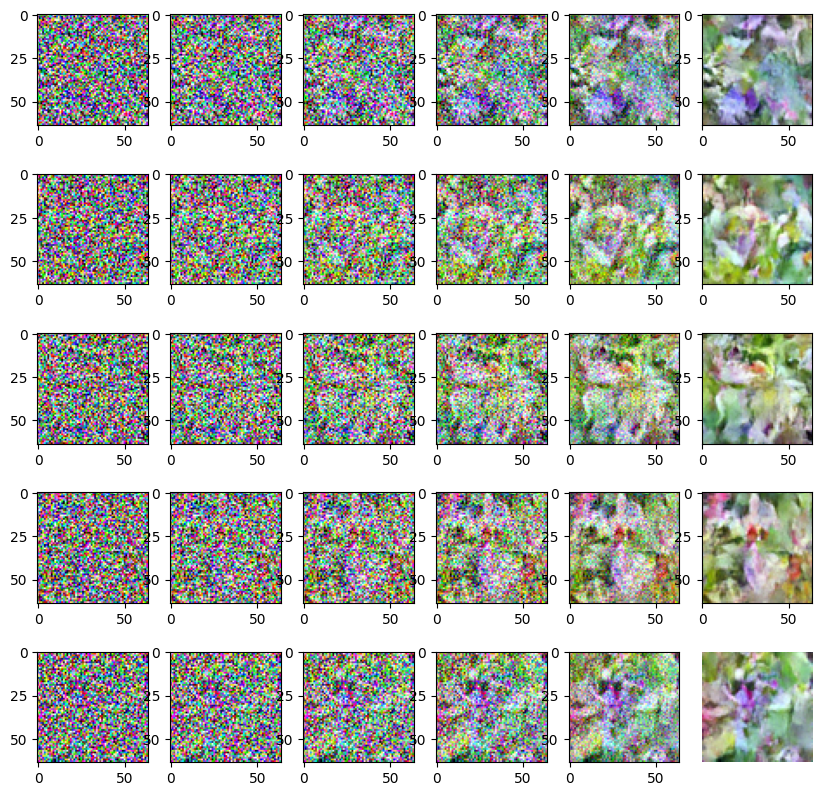

In [12]:
#sample testing
checkpoint_path="./final_diffusion_model.pt"
state_dict = torch.load(checkpoint_path, map_location=device)
diffusion.load_state_dict(state_dict)

diffusion.eval()
raw_tensors = diffusion.sample(num_images=5,channels=3, size=64, steps=50, show_change=True, device=device)

processed_images = (raw_tensors + 1.0) / 2.0 #rescale the image
processed_images = torch.clamp(processed_images, 0.0, 1.0)
fix, axes=plt.subplots(5, 6, figsize=(10, 10))

for i in range(5):
    for j in range(6):
        img=processed_images[i, j].detach().cpu().permute(1, 2, 0).numpy()   #(C, H, W) to (H, W, C) for matplotlib
        axes[i, j].imshow(img)
plt.savefig("denoised_samples.png")
plt.axis('off')
plt.show()
